PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [ ]:
df = pd.read_csv(localized_url('/Users/yarkin/Desktop/Dissertation/statistical-analysis-and-modeling-of-football-data/Understat/Data/understat_match_1524.csv'))

In [4]:
df.columns

Index(['id', 'fid', 'h', 'a', 'date', 'league_id', 'season', 'h_goals',
       'a_goals', 'team_h', 'team_a', 'h_xg', 'a_xg', 'h_w', 'h_d', 'h_l',
       'league', 'h_shot', 'a_shot', 'h_shotOnTarget', 'a_shotOnTarget',
       'h_deep', 'a_deep', 'a_ppda', 'h_ppda'],
      dtype='object')

In [5]:
df["h_result"] = np.where(df["h_goals"] > df["a_goals"], "W", np.where(df["h_goals"] < df["a_goals"], "L", "D"))
df["a_result"] = np.where(df["h_goals"] < df["a_goals"], "W", np.where(df["h_goals"] > df["a_goals"], "L", "D"))

In [6]:
features = ['h_goals',
       'a_goals', 'h_xg', 'a_xg', 'h_shot', 'a_shot', 'h_shotOnTarget', 'a_shotOnTarget',
       'h_deep', 'a_deep', 'a_ppda', 'h_ppda', "h_result", "a_result"]

In [7]:
def pivot_df(df, features):
    home_features = [col for col in df[features] if col.startswith('h_')]
    home_df = df[home_features + ["id", "h", "team_h", "date", "season"]].copy()
    home_df.columns = [col.replace('h_', '') if col in home_features else col for col in home_df.columns]
    home_df.rename(columns={"h": "team_id", "team_h": "team_name"}, inplace=True)
    home_df["h_a"] = "h"

    away_features = [col for col in df[features] if col.startswith('a_')]
    away_df = df[away_features + ["id", "a", "team_a", "date", "season"]].copy()
    away_df.columns = [col.replace('a_', '') if col in away_features else col for col in away_df.columns]
    away_df.rename(columns={"a": "team_id", "team_a": "team_name"}, inplace=True)
    away_df["h_a"] = "a"

    return pd.concat([home_df, away_df], axis=0)

In [8]:
df_pivoted = pivot_df(df, features)

In [9]:
feature_list = ['goals', 'xg', 'shot', 'shotOnTarget', 'deep', "ppda"]

In [10]:
df_pivoted["Shots on target per shot"] = df_pivoted["shotOnTarget"] / df_pivoted["shot"]
df_pivoted["xG per shot"] = df_pivoted["xg"] / df_pivoted["shot"]
df_pivoted["Goals per shot"] = df_pivoted["goals"] / df_pivoted["shot"]
df_pivoted["goals per xG"] = df_pivoted["goals"] / df_pivoted["xg"]

feature_list.append("Shots on target per shot")
feature_list.append("goals per xG")
feature_list.append("xG per shot")
feature_list.append("Goals per shot")

In [11]:
df_pivoted

,goals,xg,shot,shotOnTarget,deep,ppda,result,id,team_id,team_name,date,season,h_a,Shots on target per shot,xG per shot,Goals per shot,goals per xG
0,1,0.627539,9,1,4,13.8261,W,81,89,Manchester United,2015-08-08 15:45:00,2015,h,0.111111,0.069727,0.111111,1.593526
1,0,0.876106,11,2,11,6.9000,L,82,73,Bournemouth,2015-08-08 18:00:00,2015,h,0.181818,0.079646,0.000000,0.000000
2,2,0.604226,10,5,5,6.6500,D,83,72,Everton,2015-08-08 18:00:00,2015,h,0.500000,0.060423,0.200000,3.310020
3,4,2.568030,19,8,5,10.8800,W,84,75,Leicester,2015-08-08 18:00:00,2015,h,0.421053,0.135159,0.210526,1.557614
4,1,1.130760,17,6,5,5.7368,L,85,79,Norwich,2015-08-08 18:00:00,2015,h,0.352941,0.066515,0.058824,0.884361
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,0,0.598846,8,2,0,30.3000,L,22270,71,Aston Villa,2024-05-19 15:00:00,2023,a,0.250000,0.074856,0.000000,0.000000
3416,0,0.731254,4,3,1,16.6000,L,22271,229,Wolverhampton Wanderers,2024-05-19 15:00:00,2023,a,0.750000,0.182813,0.000000,0.000000
3417,4,1.115980,15,7,5,10.5000,W,22272,228,Fulham,2024-05-19 15:00:00,2023,a,0.466667,0.074399,0.266667,3.584294
3418,1,0.240159,3,2,0,63.0000,L,22273,81,West Ham,2024-05-19 15:00:00,2023,a,0.666667,0.080053,0.333333,4.163908


In [12]:
df_pivoted[(df_pivoted['team_name'] == 'Manchester City') & (df_pivoted['h_a'] == 'h')& (df_pivoted['season'] == 2023)]["result"].value_counts()

result
W    14
D     5
Name: count, dtype: int64

In [13]:
df_pivoted[(df_pivoted['team_name'] == 'Nottingham Forest') & (df_pivoted['h_a'] == 'a')]["result"].value_counts()

result
L    24
D     9
W     5
Name: count, dtype: int64

In [14]:
team_summaries_seasonal_df = df_pivoted.groupby(['team_id', 'team_name', 'season']).agg({
    feature: "mean" for feature in feature_list
}).reset_index()

In [15]:
team_summaries_seasonal_df

,team_id,team_name,season,goals,xg,shot,shotOnTarget,deep,ppda,Shots on target per shot,goals per xG,xG per shot,Goals per shot
0,71,Aston Villa,2015,0.710526,0.698081,10.000000,2.894737,3.578947,13.835947,0.283798,1.059655,0.065695,0.070144
1,71,Aston Villa,2019,1.078947,1.186552,12.052632,3.894737,4.894737,13.377100,0.321748,0.869094,0.101974,0.088602
2,71,Aston Villa,2020,1.447368,1.492513,13.710526,4.921053,7.210526,11.674768,0.353882,0.938602,0.105713,0.104869
3,71,Aston Villa,2021,1.368421,1.134988,12.184211,4.263158,6.789474,14.201018,0.350796,1.374073,0.094549,0.124996
4,71,Aston Villa,2022,1.342105,1.315667,11.315789,3.973684,6.789474,13.397116,0.359927,1.339009,0.116711,0.141259
...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,245,Leeds,2021,1.105263,1.347002,12.763158,4.052632,6.289474,10.310350,0.321811,0.738299,0.105443,0.083196
176,245,Leeds,2022,1.263158,1.257789,12.131579,3.815789,6.052632,10.930971,0.320831,1.187739,0.100210,0.106600
177,249,Nottingham Forest,2022,1.000000,1.041433,9.684211,3.105263,4.131579,18.332976,0.322129,1.003564,0.110787,0.105574
178,249,Nottingham Forest,2023,1.289474,1.372561,11.868421,3.894737,5.605263,21.254934,0.334830,1.029149,0.114181,0.113630


In [16]:
season_list= team_summaries_seasonal_df['season'].unique().tolist()
# Plot the best team for every feature for every season
def plot_best_teams_by_feature(team_summaries_seasonal_df, season_list):
    team_feature_by_season = {}
    for season in season_list:
        best_team = team_summaries_seasonal_df[team_summaries_seasonal_df['season'] == season].sort_values(by=feature, ascending=False)
        best_team_name = best_team.iloc[0]['team_name']
        best_team_feature = best_team.iloc[0][feature]
        team_feature_by_season[season] = (best_team_name, best_team_feature)

    # Plotting x as season, y as feature with different colors for different teams
    seasons = list(team_feature_by_season.keys())
    feature_values = [team_feature_by_season[season][1] for season in seasons]
    team_names = [team_feature_by_season[season][0] for season in seasons]
    plt.figure(figsize=(12, 6))
    sns.barplot(x=seasons, y=feature_values, hue=team_names, dodge=False)
    plt.title(f'Highest Value Team by {feature} for Each Season')
    plt.xlabel('Season')
    plt.ylabel(feature)
    plt.legend(title='Team', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

    

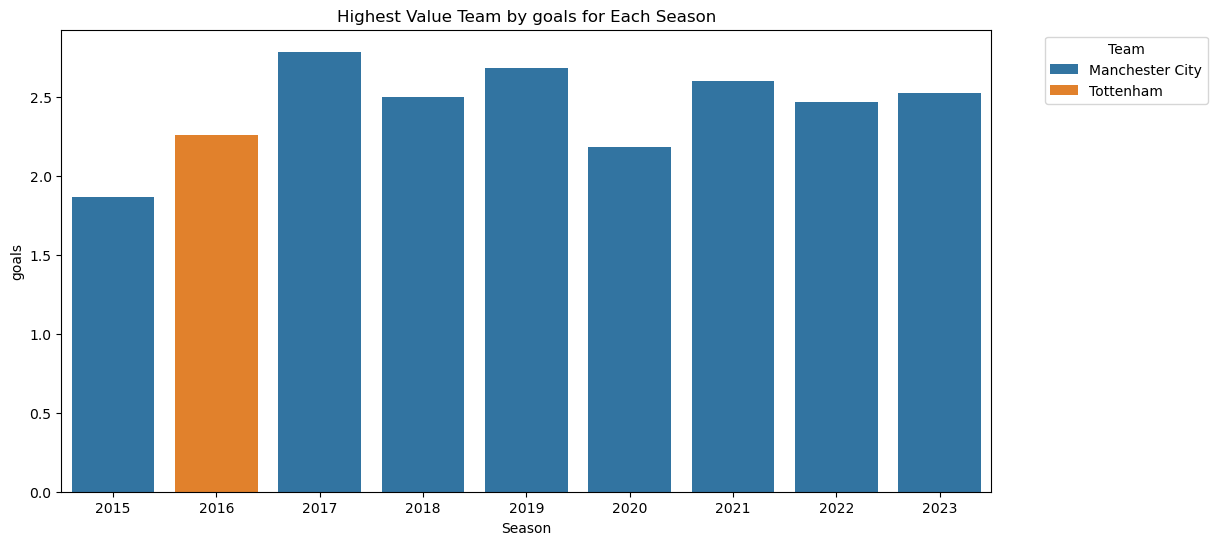

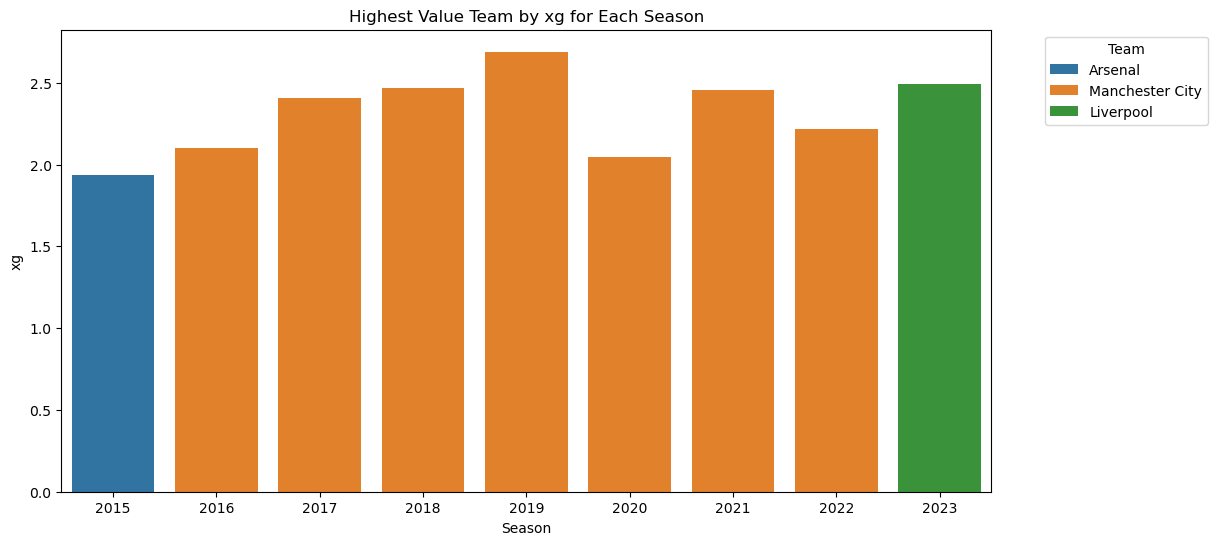

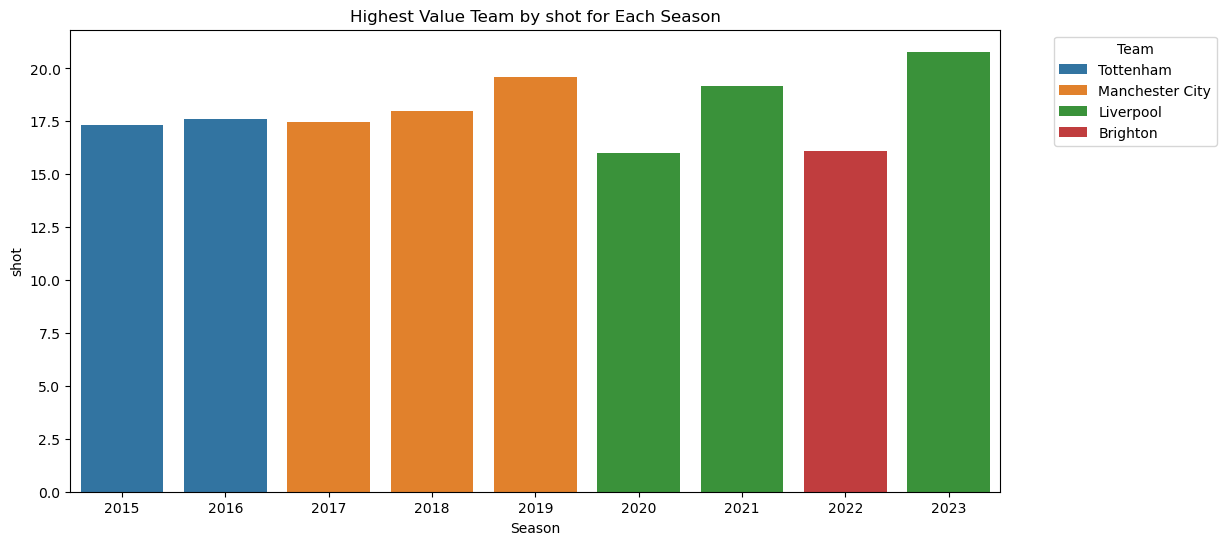

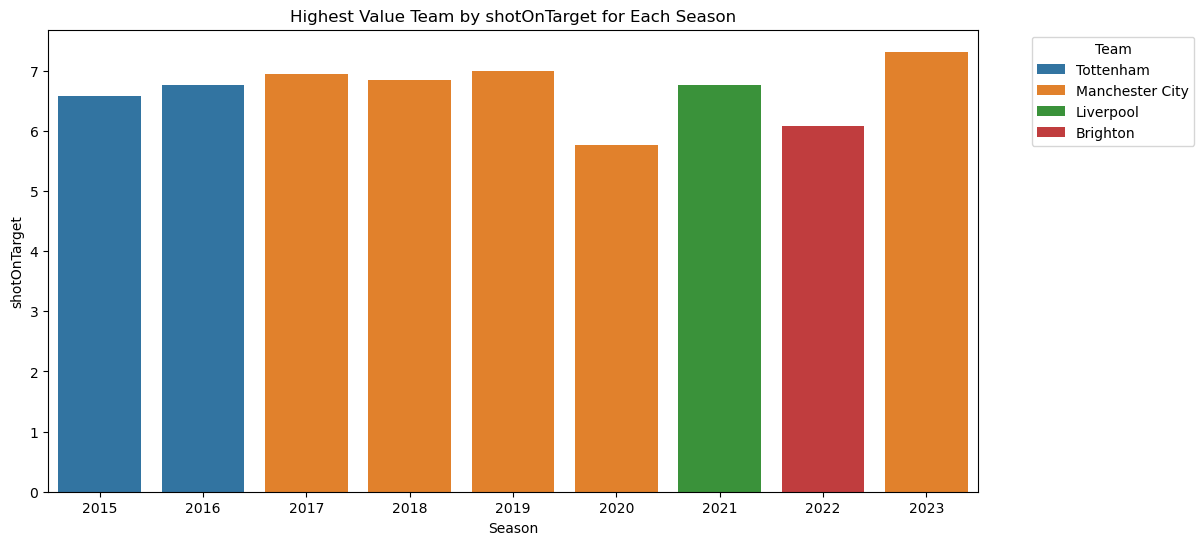

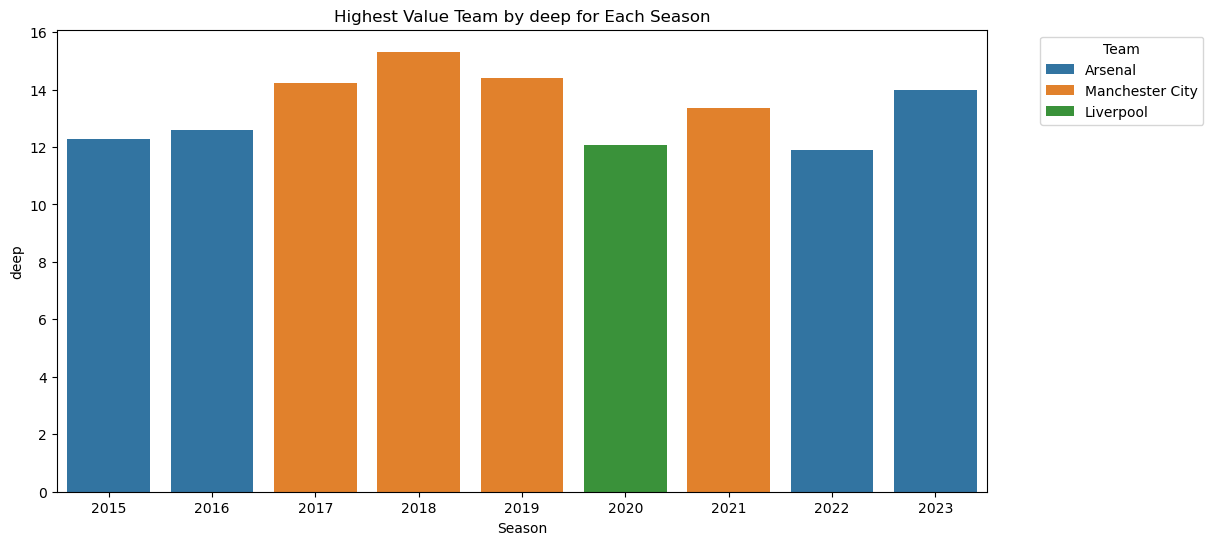

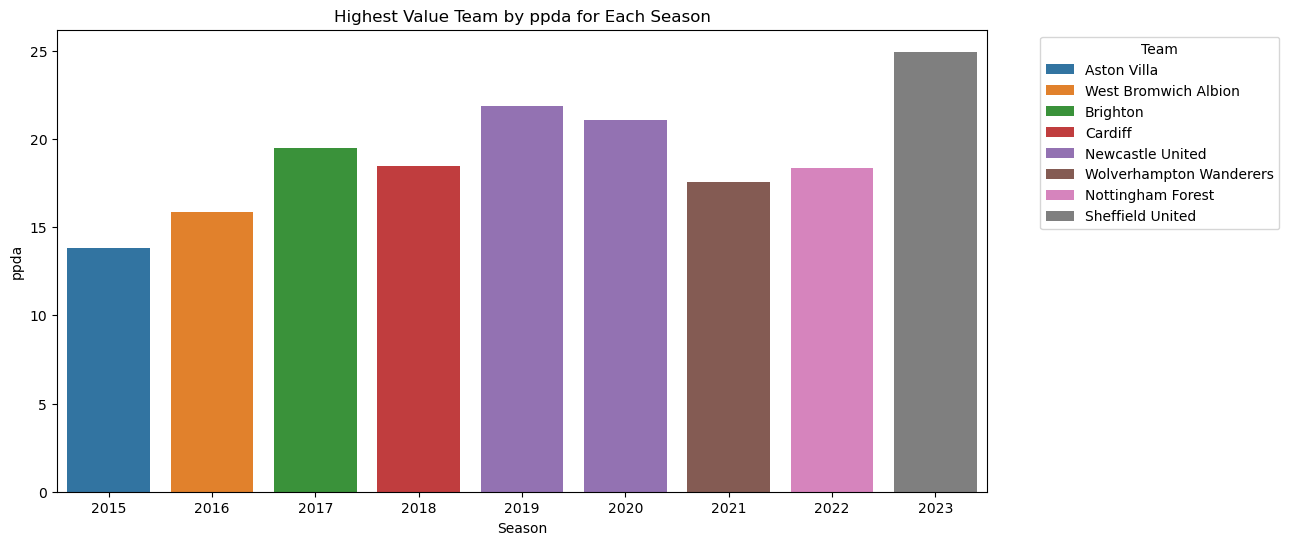

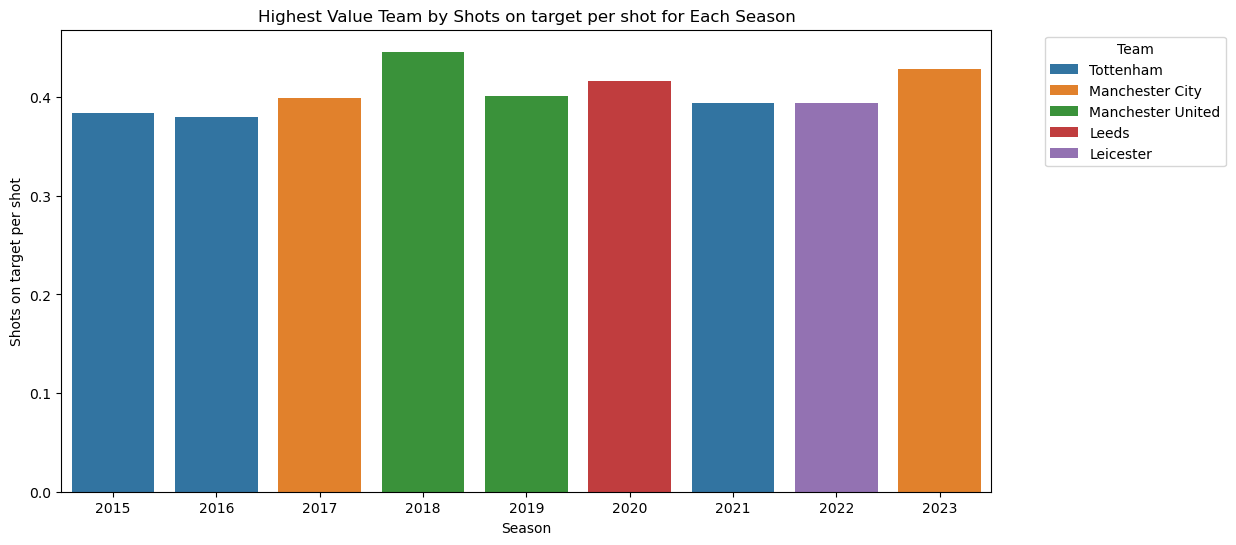

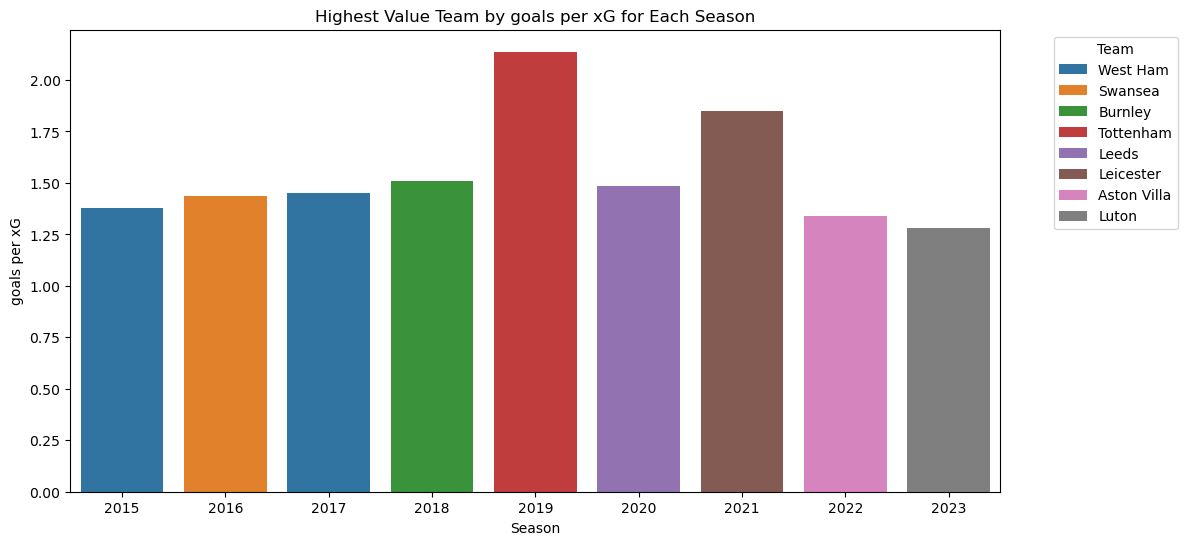

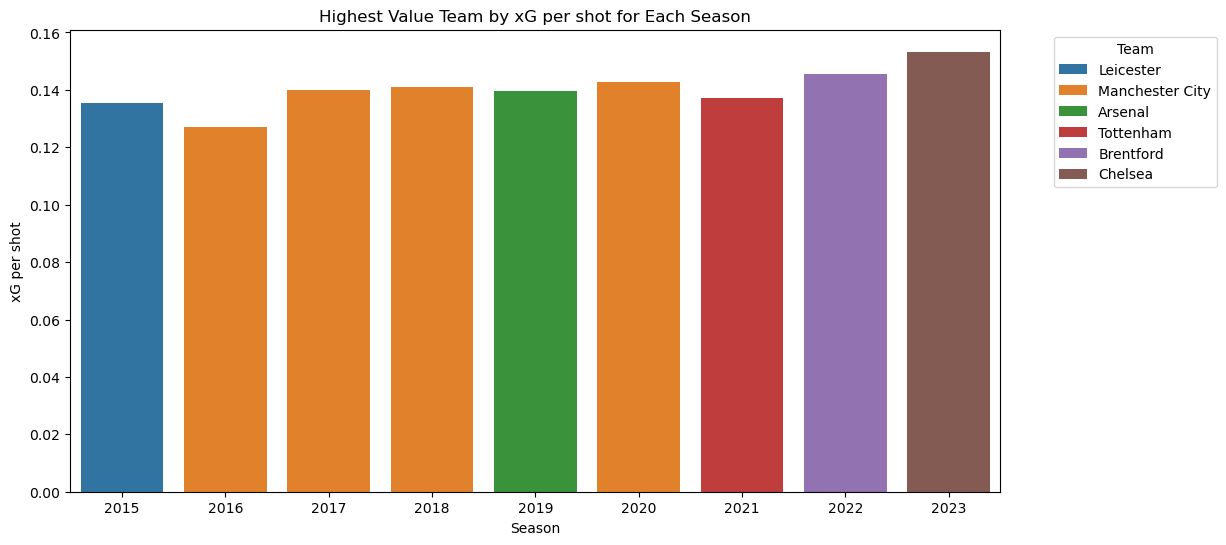

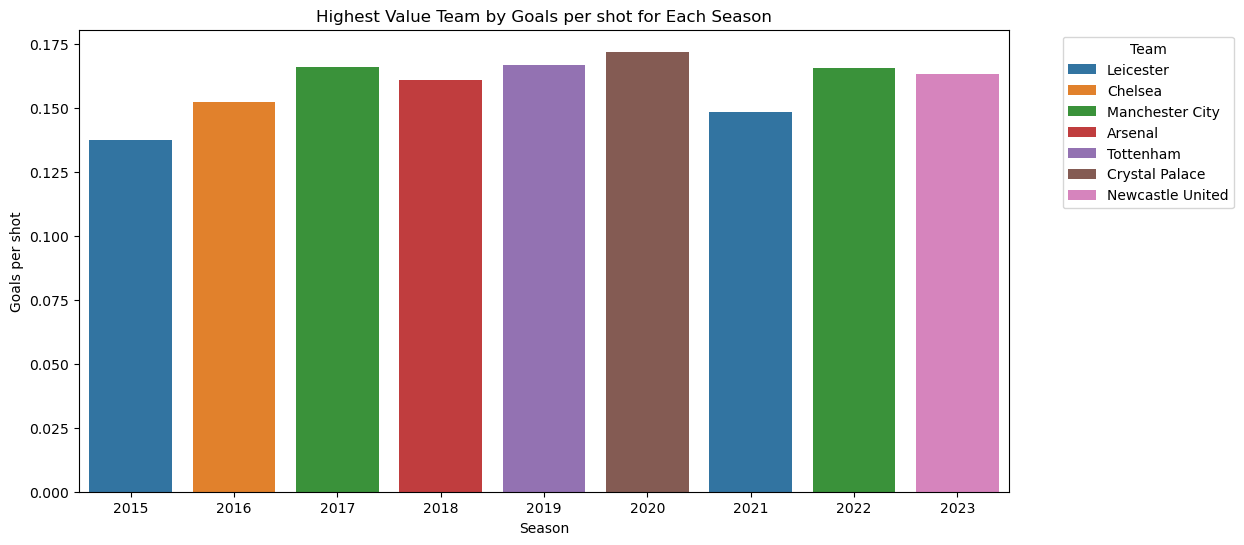

In [17]:
for feature in feature_list:
    plot_best_teams_by_feature(team_summaries_seasonal_df, season_list)

In [18]:

# Plot the best team for every feature for every season
def plot_lowest_teams_by_feature(team_summaries_seasonal_df, season_list):
    team_feature_by_season = {}
    for season in season_list:
        best_team = team_summaries_seasonal_df[team_summaries_seasonal_df['season'] == season].sort_values(by=feature, ascending=True)
        best_team_name = best_team.iloc[0]['team_name']
        best_team_feature = best_team.iloc[0][feature]
        team_feature_by_season[season] = (best_team_name, best_team_feature)

    # Plotting x as season, y as feature with different colors for different teams
    seasons = list(team_feature_by_season.keys())
    feature_values = [team_feature_by_season[season][1] for season in seasons]
    team_names = [team_feature_by_season[season][0] for season in seasons]
    plt.figure(figsize=(12, 6))
    sns.barplot(x=seasons, y=feature_values, hue=team_names, dodge=False)
    plt.title(f'Highest Value Team by {feature} for Each Season')
    plt.xlabel('Season')
    plt.ylabel(feature)
    plt.legend(title='Team', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

    

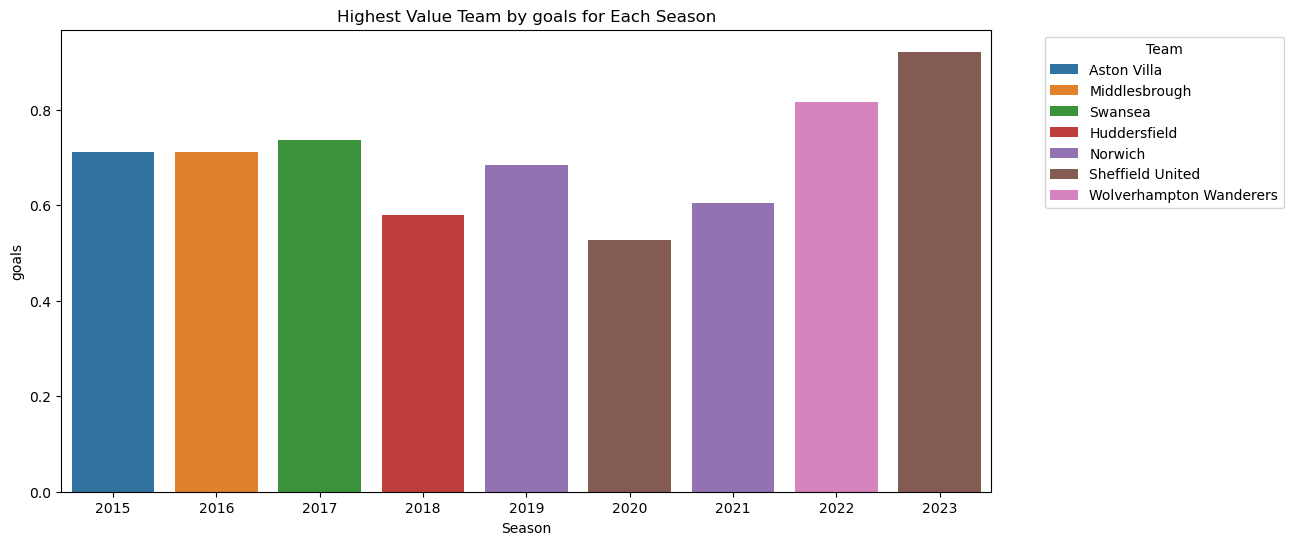

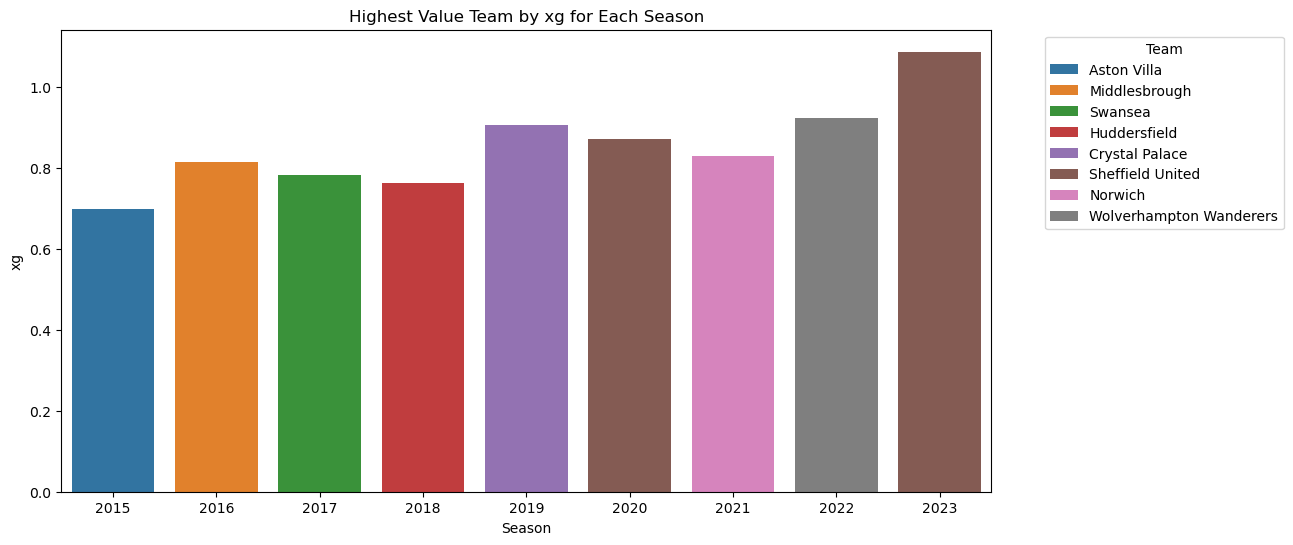

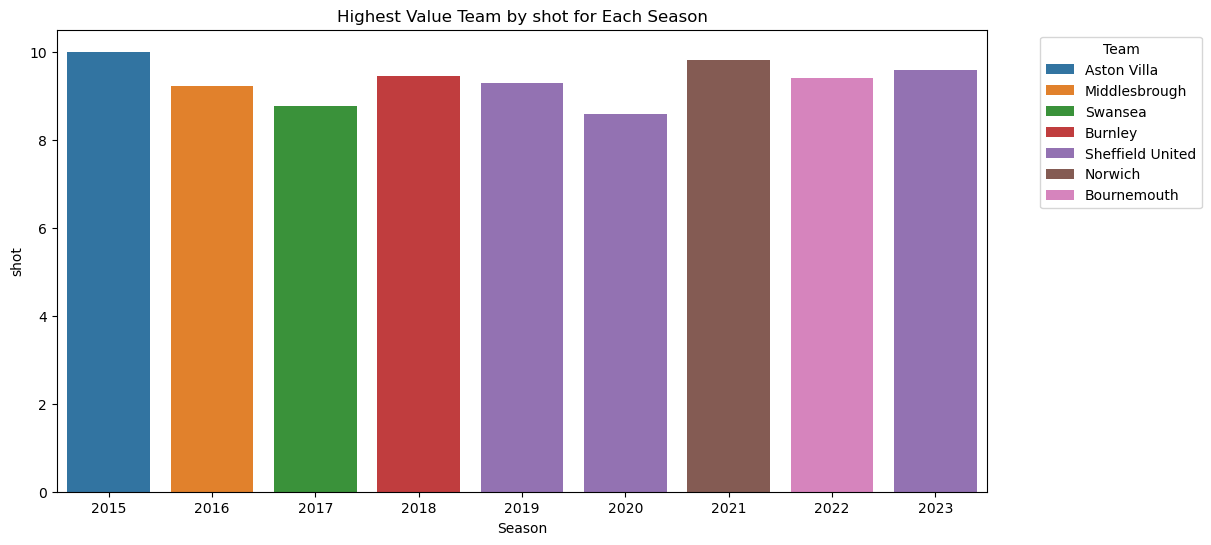

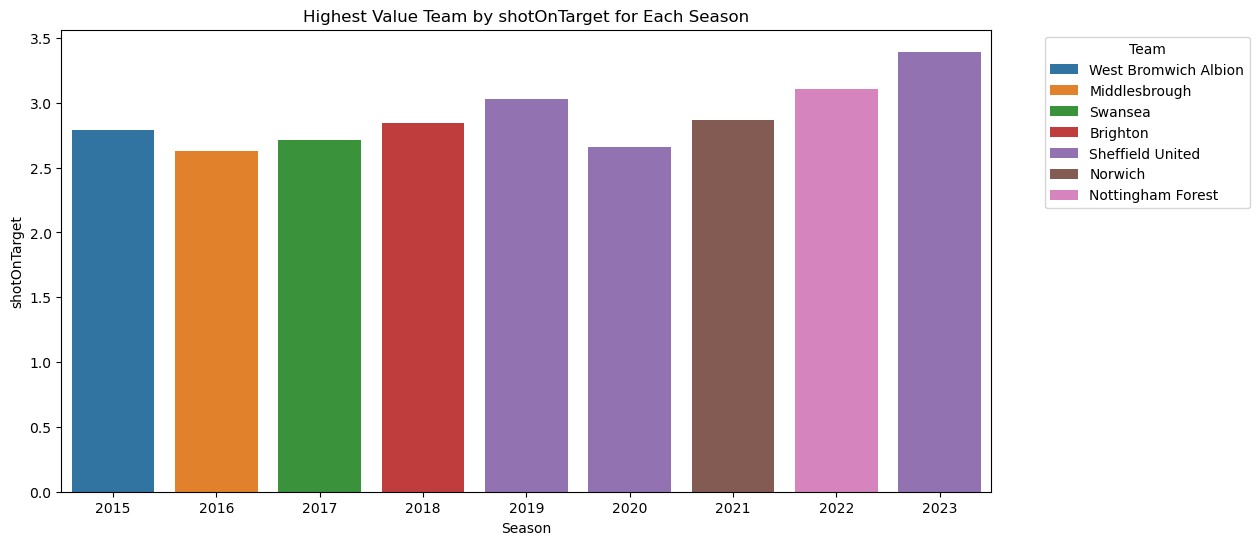

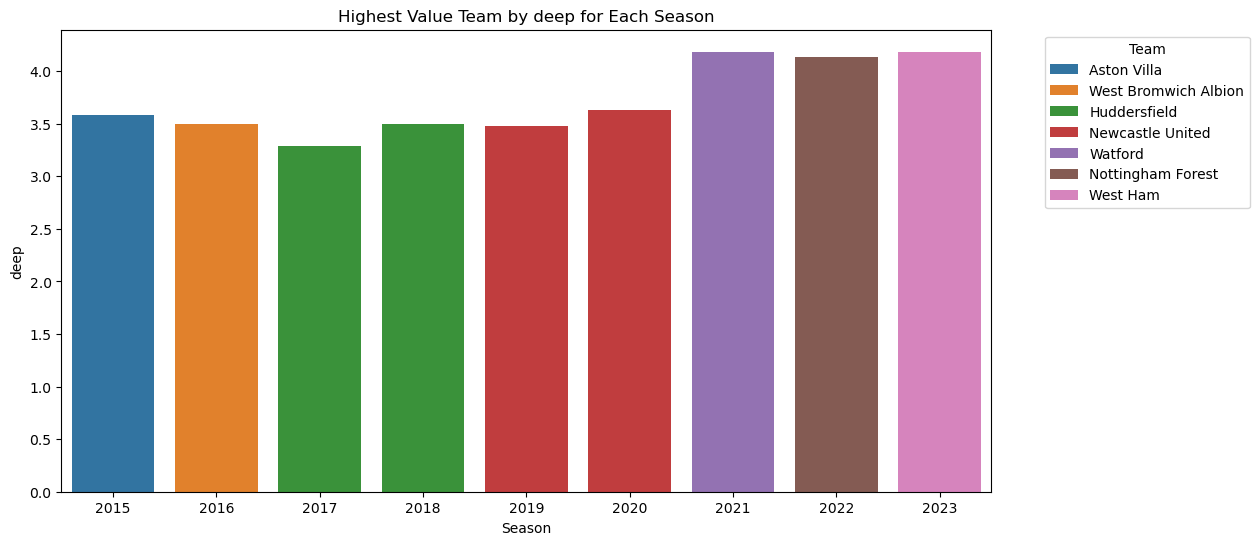

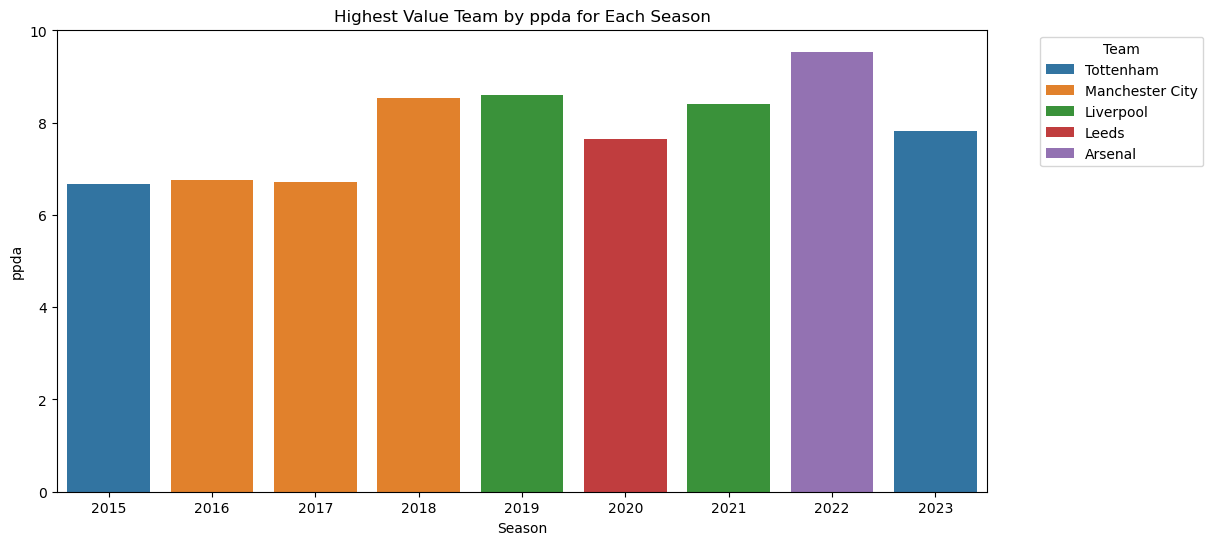

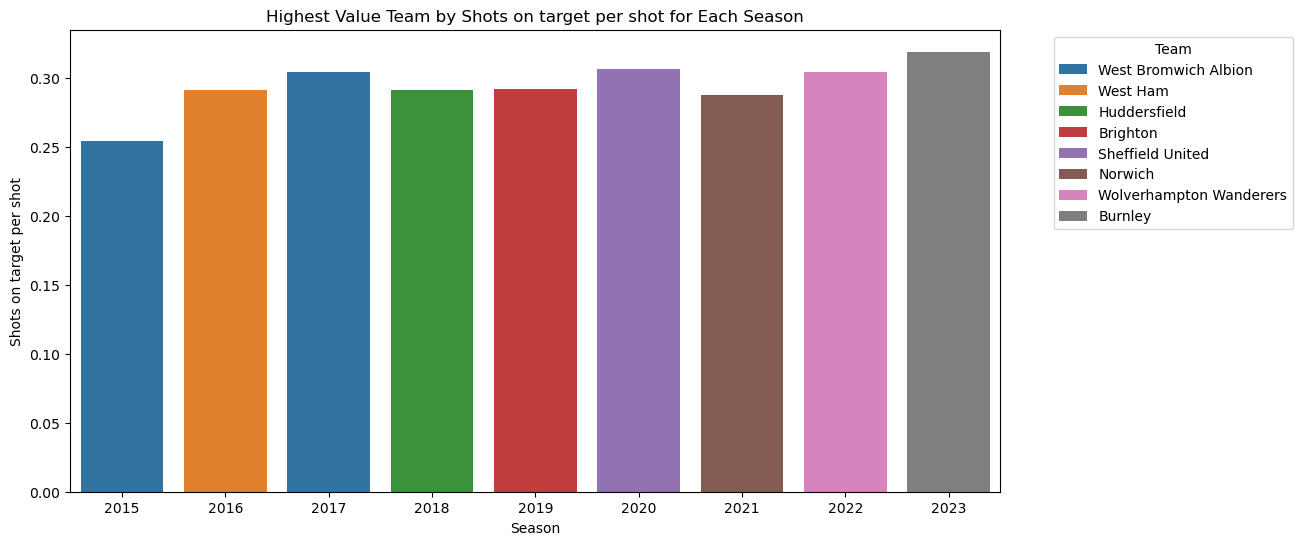

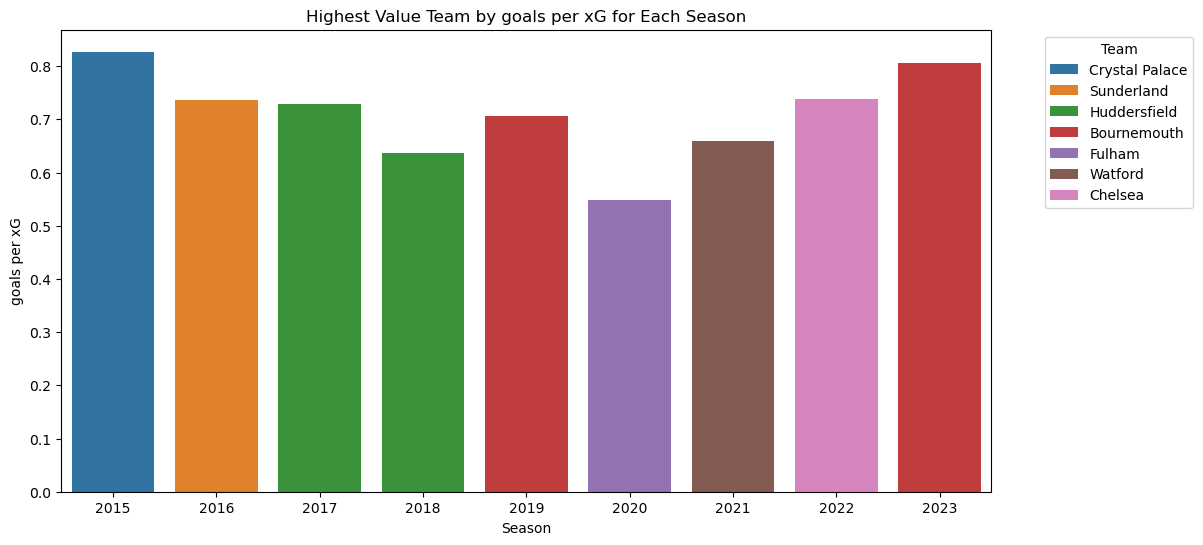

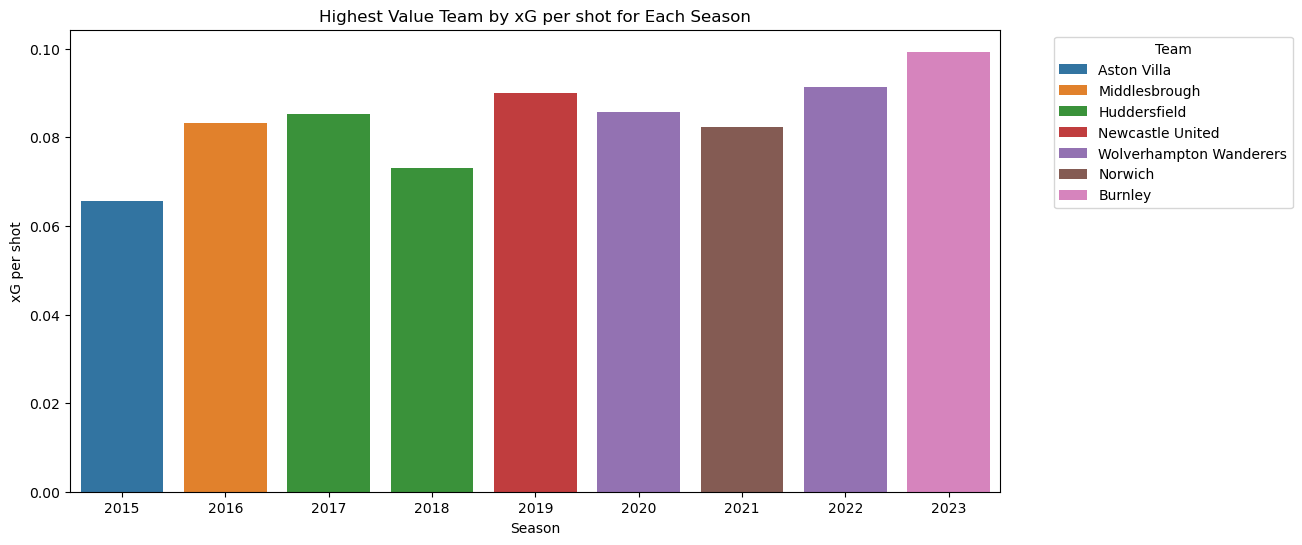

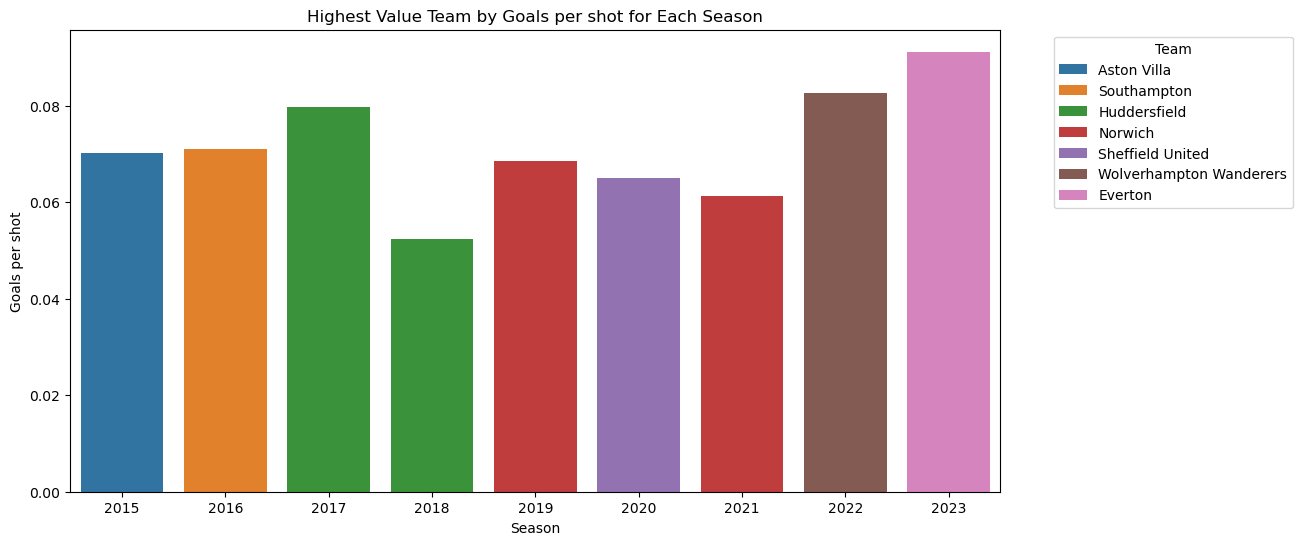

In [19]:
for feature in feature_list:
    plot_lowest_teams_by_feature(team_summaries_seasonal_df, season_list)

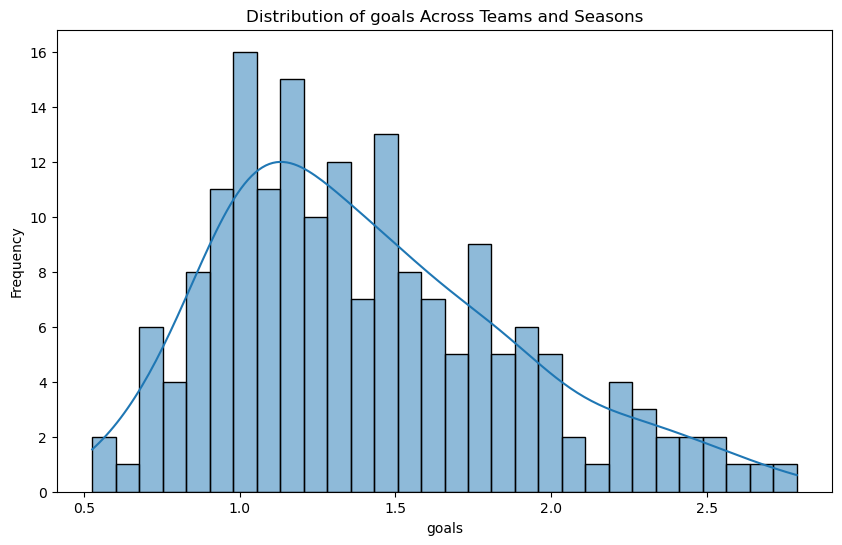

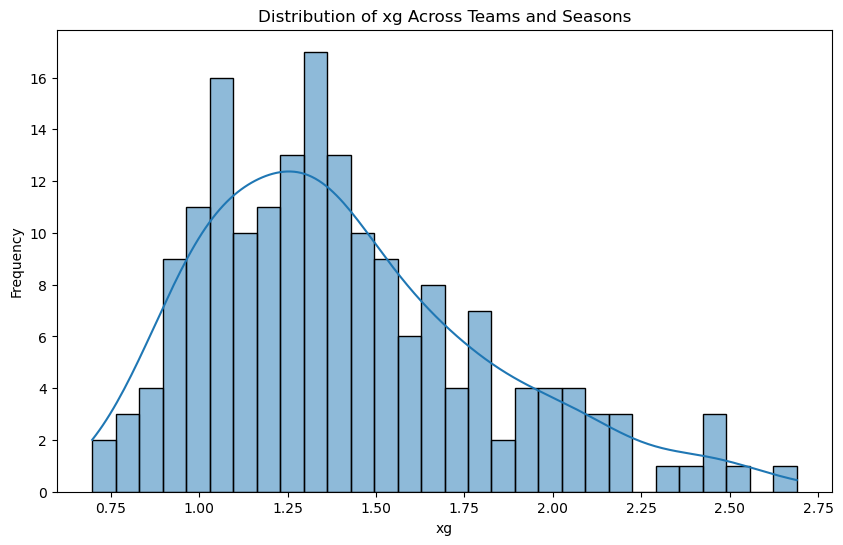

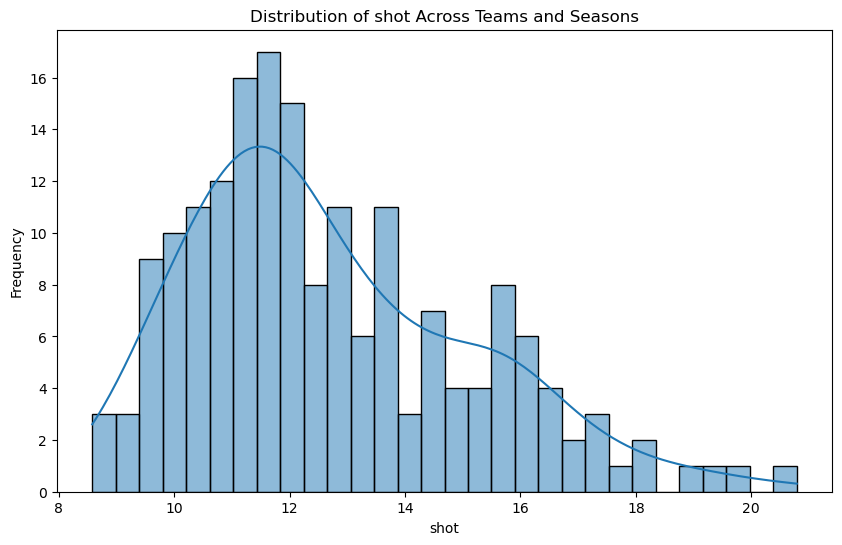

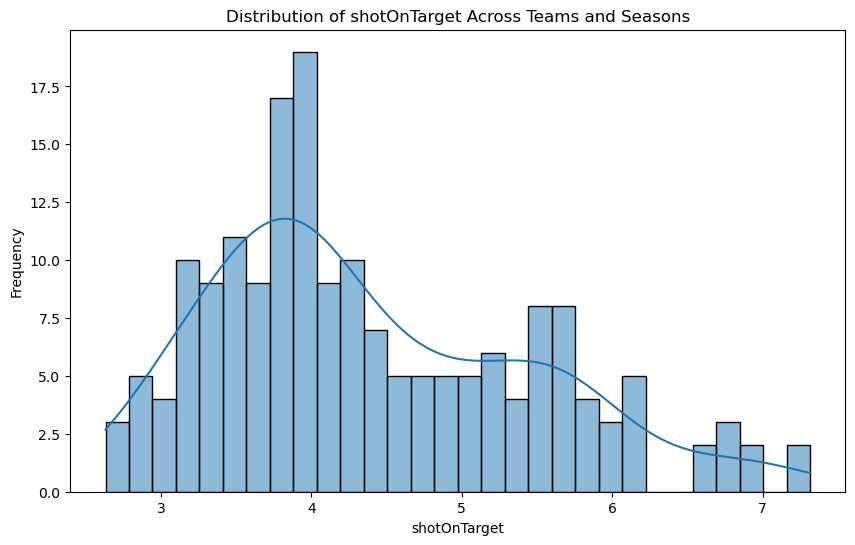

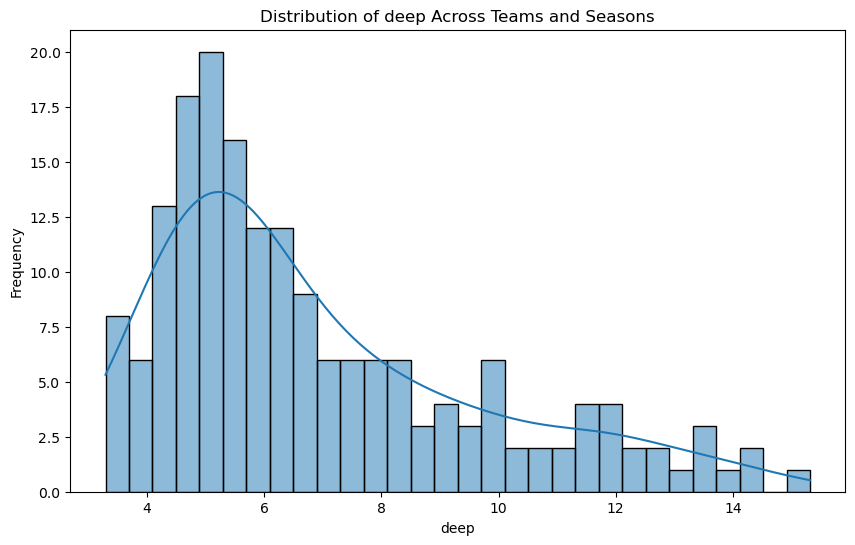

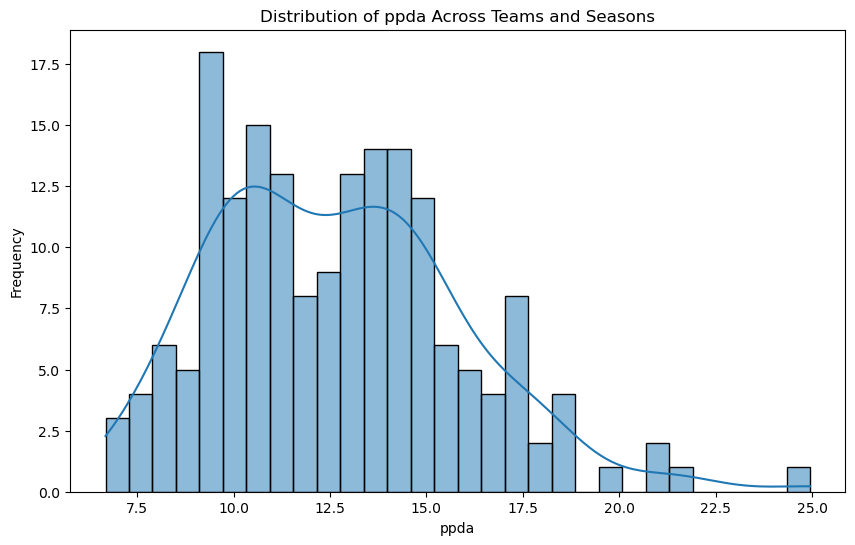

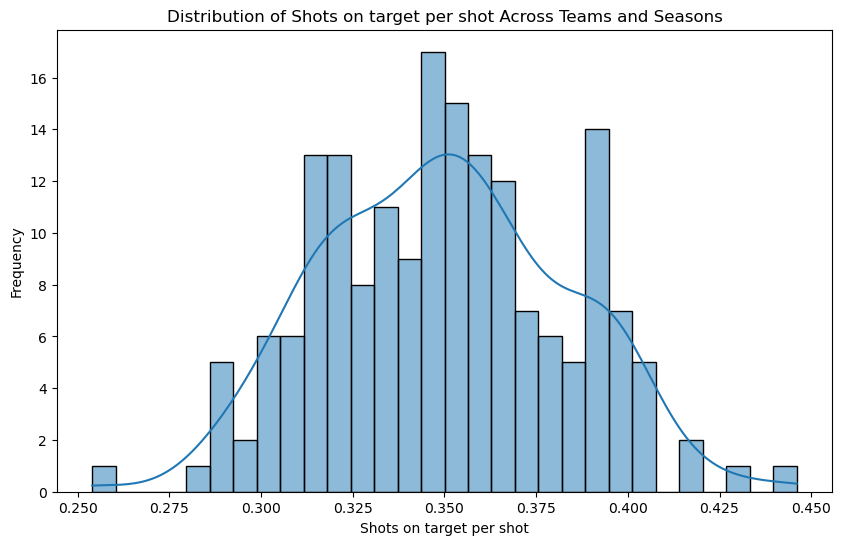

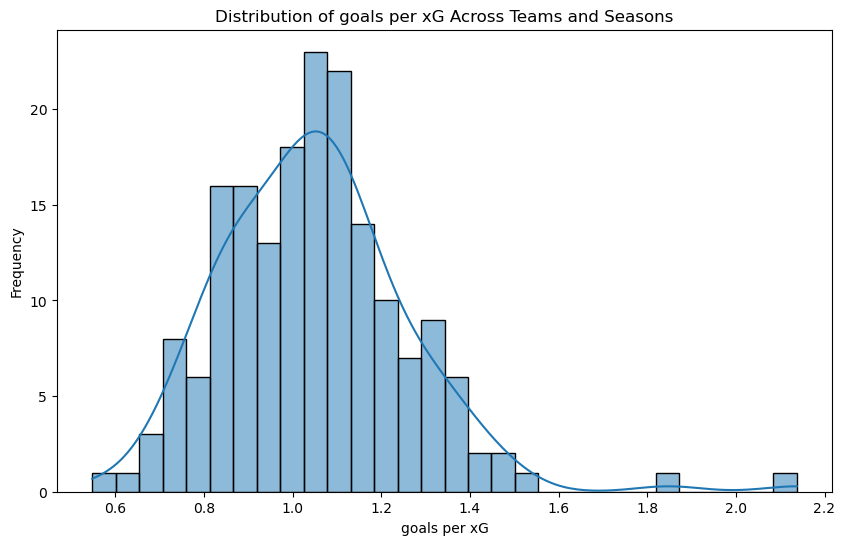

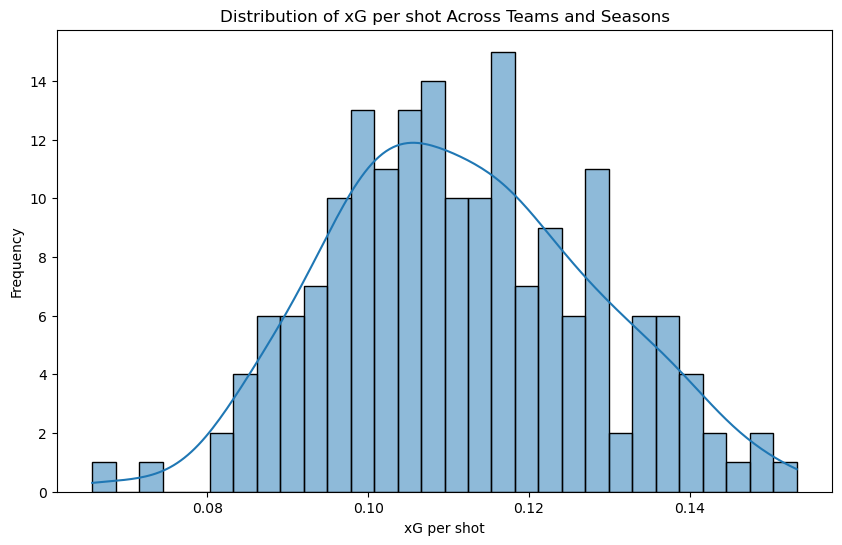

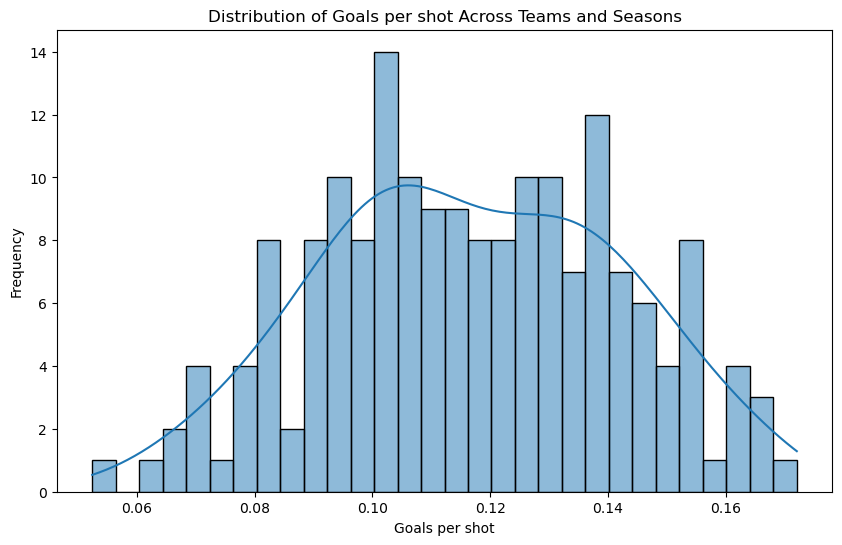

In [22]:
# Plot distribution for each feature
for feature in feature_list:
    plt.figure(figsize=(10, 6))
    sns.histplot(team_summaries_seasonal_df[feature], bins=30, kde=True)
    plt.title(f'Distribution of {feature} Across Teams and Seasons')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()